In [325]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [326]:
import os

print(os.listdir("/content/drive/MyDrive"))

['Colab Notebooks', 'Untitled Diagram.drawio', 'Code (6)', 'Code (5)', 'Code (4)', 'Code (3)', 'Code (2)', 'Code (1)', 'Code', 'Crop Disease AI project', 'Member 05', 'class_distribution.png', 'class_distribution.csv', 'class_weights.csv', 'Group_AIML', 'IT25103052_Class_imbalance_handling.ipynb', 'IT25103052_class_distribution.png', 'IT25103052_class_weights.png']


In [327]:
PROJECT_DIR = "/content/drive/MyDrive/Group_AIML"

In [328]:
import os

print(os.listdir(PROJECT_DIR))

['Member 07_IT25103599 ', 'Member 05_IT25103052', '07_Notebooks', '05_EDA Visualization', '03_Final_Output', 'Member 02_IT25103229', '02_Group_Pipeline', 'Member 01_IT25103233', 'Member 03_IT25103371', 'Member 06_IT25103274', 'Member 04_IT25103567', '01_Raw DataSet', '06_Readme']


In [329]:
MEMBER7_DIR = os.path.join(PROJECT_DIR, "Member 07_IT25103599 ")

print(os.listdir(MEMBER7_DIR))

['Outputs', 'Notebook', 'EDA']


In [330]:
MEMBER7_OUTPUTS = os.path.join(MEMBER7_DIR, "Outputs")

print(os.listdir(MEMBER7_OUTPUTS))

['train_quality_enhanced_images.npy', 'train_quality_manifest.csv', 'validation_quality_enhanced_images.npy', 'validation_quality_manifest.csv', 'train_labels.npy', 'validation_labels.npy', 'quality_metrics_audit.csv']


In [331]:
# Import NumPy for loading and analyzing the label data
import numpy as np

# Define the path to the training labels from Member 7's output
LABELS_PATH = os.path.join(MEMBER7_OUTPUTS, "train_labels.npy")

# Load the training labels
train_labels = np.load(LABELS_PATH, allow_pickle=True)

# Verify that the labels were loaded correctly
print("Labels loaded successfully!")
print("Number of training samples:", len(train_labels))
print("Shape:", train_labels.shape)

Labels loaded successfully!
Number of training samples: 11662
Shape: (11662,)


In [332]:
# Inspect the training labels before class imbalance analysis

# Display the first 20 training labels
print("First 20 labels:")
print(train_labels[:20])

# Display all unique classes in the training dataset
print("\nUnique classes:")
print(np.unique(train_labels))

# Confirm the total number of classes
print("\nNumber of classes:")
print(len(np.unique(train_labels)))

First 20 labels:
['Wilt' 'Wilt' 'Wilt' 'Wilt' 'Wilt' 'Wilt' 'Wilt' 'Wilt' 'Wilt' 'Wilt'
 'Wilt' 'Wilt' 'Wilt' 'Wilt' 'Wilt' 'Wilt' 'Wilt' 'Wilt' 'Wilt' 'Wilt']

Unique classes:
['Becterial Blight in Rice' 'Brownspot' 'Gray_Leaf_Spot' 'Healthy Maize'
 'Healthy Wheat' 'Healthy cotton' 'Mosaic sugarcane' 'RedRot sugarcane'
 'Rice Blast' 'Sugarcane Healthy' 'Tungro' 'Wheat Stem fly'
 'Wheat black rust' 'Wheat powdery mildew' 'Wilt'
 'bacterial_blight in Cotton' 'cotton mealy bug' 'maize fall armyworm'
 'maize stem borer' 'red cotton bug']

Number of classes:
20


In [333]:
# Count the number of training samples in each class
unique_classes, class_counts = np.unique(train_labels, return_counts=True)

# Display the class distribution
print("Class Distribution:\n")

for class_name, count in zip(unique_classes, class_counts):
    print(f"{class_name}: {count}")

Class Distribution:

Becterial Blight in Rice: 1584
Brownspot: 1640
Gray_Leaf_Spot: 574
Healthy Maize: 1162
Healthy Wheat: 180
Healthy cotton: 425
Mosaic sugarcane: 462
RedRot sugarcane: 592
Rice Blast: 1440
Sugarcane Healthy: 522
Tungro: 1308
Wheat Stem fly: 172
Wheat black rust: 161
Wheat powdery mildew: 169
Wilt: 419
bacterial_blight in Cotton: 489
cotton mealy bug: 92
maize fall armyworm: 107
maize stem borer: 95
red cotton bug: 69


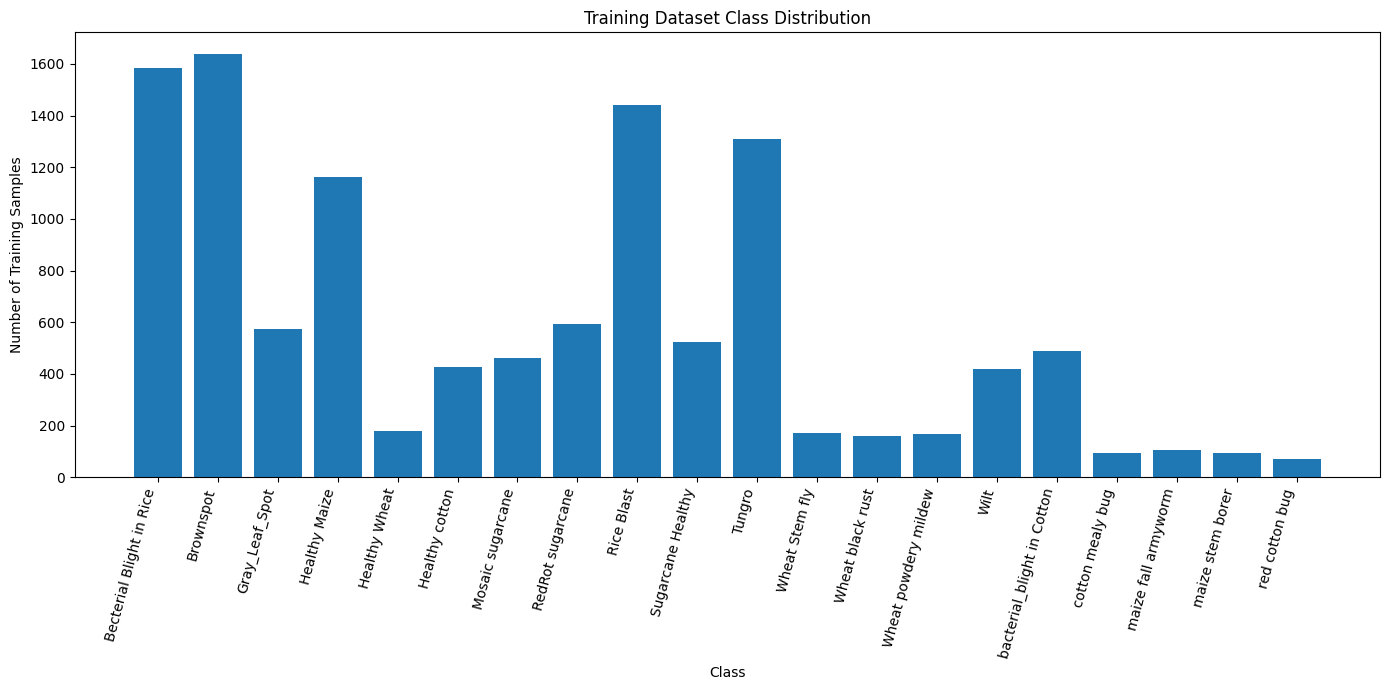

Class distribution graph saved successfully!


In [334]:
# Import Matplotlib for visualization
import matplotlib.pyplot as plt

# Define Member 05 folder
MEMBER5_DIR = os.path.join(PROJECT_DIR, "Member 05_IT25103052")

# Define Member 05 EDA folder
EDA_DIR = os.path.join(MEMBER5_DIR, "EDA")

# Create the class distribution bar chart
plt.figure(figsize=(14, 7))

plt.bar(unique_classes, class_counts)

# Add chart title and axis labels
plt.title("Training Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Training Samples")

# Rotate class names for better readability
plt.xticks(rotation=75, ha="right")

plt.tight_layout()

# Save the EDA graph with the IT number
plt.savefig(
    os.path.join(EDA_DIR, "IT25103052_class_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

# Display the graph
plt.show()

print("Class distribution graph saved successfully!")

In [335]:
# Identify the class with the highest number of samples
max_index = np.argmax(class_counts)

# Identify the class with the lowest number of samples
min_index = np.argmin(class_counts)

# Get the class names and sample counts
largest_class = unique_classes[max_index]
largest_count = class_counts[max_index]

smallest_class = unique_classes[min_index]
smallest_count = class_counts[min_index]

# Calculate the imbalance ratio
imbalance_ratio = largest_count / smallest_count

# Display the results
print("Largest class:", largest_class, "-", largest_count, "samples")
print("Smallest class:", smallest_class, "-", smallest_count, "samples")
print("Imbalance ratio:", round(imbalance_ratio, 2), ": 1")

Largest class: Brownspot - 1640 samples
Smallest class: red cotton bug - 69 samples
Imbalance ratio: 23.77 : 1


In [336]:
# Import the function used to calculate balanced class weights
from sklearn.utils.class_weight import compute_class_weight

# Calculate a weight for each class based on its frequency
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=unique_classes,
    y=train_labels
)

# Display the calculated weight for each class
print("Calculated Class Weights:\n")

for class_name, weight in zip(unique_classes, class_weights):
    print(f"{class_name}: {weight:.4f}")

Calculated Class Weights:

Becterial Blight in Rice: 0.3681
Brownspot: 0.3555
Gray_Leaf_Spot: 1.0159
Healthy Maize: 0.5018
Healthy Wheat: 3.2394
Healthy cotton: 1.3720
Mosaic sugarcane: 1.2621
RedRot sugarcane: 0.9850
Rice Blast: 0.4049
Sugarcane Healthy: 1.1170
Tungro: 0.4458
Wheat Stem fly: 3.3901
Wheat black rust: 3.6217
Wheat powdery mildew: 3.4503
Wilt: 1.3916
bacterial_blight in Cotton: 1.1924
cotton mealy bug: 6.3380
maize fall armyworm: 5.4495
maize stem borer: 6.1379
red cotton bug: 8.4507


In [337]:
# Create a table containing each class and its calculated weight
class_weights_df = pd.DataFrame({
    "Class_Name": unique_classes,
    "Class_Weight": class_weights
})

# Display the calculated class weights
print("Calculated Class Weights:\n")
print(class_weights_df)

Calculated Class Weights:

                    Class_Name  Class_Weight
0     Becterial Blight in Rice      0.368119
1                    Brownspot      0.355549
2               Gray_Leaf_Spot      1.015854
3                Healthy Maize      0.501807
4                Healthy Wheat      3.239444
5               Healthy cotton      1.372000
6             Mosaic sugarcane      1.262121
7             RedRot sugarcane      0.984966
8                   Rice Blast      0.404931
9            Sugarcane Healthy      1.117050
10                      Tungro      0.445795
11              Wheat Stem fly      3.390116
12            Wheat black rust      3.621739
13        Wheat powdery mildew      3.450296
14                        Wilt      1.391647
15  bacterial_blight in Cotton      1.192434
16            cotton mealy bug      6.338043
17         maize fall armyworm      5.449533
18            maize stem borer      6.137895
19              red cotton bug      8.450725


In [338]:

# LOAD MEMBER 04 LABEL MAPPING

import os
import pandas as pd

# Find Member 04's folder inside Group_AIML
MEMBER4_FOLDER = [
    folder for folder in os.listdir(PROJECT_DIR)
    if folder.startswith("Member 04")
][0]

# Define Member 04 folder path
MEMBER4_DIR = os.path.join(
    PROJECT_DIR,
    MEMBER4_FOLDER
)

# Define the path to Member 04's label mapping file
LABEL_MAPPING_PATH = os.path.join(
    MEMBER4_DIR,
    "Outputs",
    "label_mapping.csv"
)

# Load the label mapping CSV
label_mapping_df = pd.read_csv(LABEL_MAPPING_PATH)

# Display the file path and mapping
print("Member 04 file loaded successfully!")
print("File path:", LABEL_MAPPING_PATH)

print("\nLabel Mapping:")
print(label_mapping_df)

Member 04 file loaded successfully!
File path: /content/drive/MyDrive/Group_AIML/Member 04_IT25103567/Outputs/label_mapping.csv

Label Mapping:
                    Class Name  Encoded Label
0     Becterial Blight in Rice              0
1                    Brownspot              1
2               Gray_Leaf_Spot              2
3                Healthy Maize              3
4                Healthy Wheat              4
5               Healthy cotton              5
6             Mosaic sugarcane              6
7             RedRot sugarcane              7
8                   Rice Blast              8
9            Sugarcane Healthy              9
10                      Tungro             10
11              Wheat Stem fly             11
12            Wheat black rust             12
13        Wheat powdery mildew             13
14                        Wilt             14
15  bacterial_blight in Cotton             15
16            cotton mealy bug             16
17         maize fall armywo

In [339]:

# COMBINE ENCODED LABELS WITH CLASS WEIGHTS
# Merge Member 04's label mapping with our calculated class weights
final_class_weights_df = pd.merge(
    label_mapping_df,
    class_weights_df,
    left_on="Class Name",
    right_on="Class_Name",
    how="inner"
)

# Remove the duplicate class-name column
final_class_weights_df = final_class_weights_df.drop(
    columns=["Class_Name"]
)

# Arrange the columns clearly
final_class_weights_df = final_class_weights_df[
    ["Encoded Label", "Class Name", "Class_Weight"]
]

# Sort according to encoded label
final_class_weights_df = final_class_weights_df.sort_values(
    by="Encoded Label"
).reset_index(drop=True)

# Display the final table
print("Final Class Weights:\n")
print(final_class_weights_df)

# Check that all 20 classes were matched
print("\nNumber of matched classes:", len(final_class_weights_df))

Final Class Weights:

    Encoded Label                  Class Name  Class_Weight
0               0    Becterial Blight in Rice      0.368119
1               1                   Brownspot      0.355549
2               2              Gray_Leaf_Spot      1.015854
3               3               Healthy Maize      0.501807
4               4               Healthy Wheat      3.239444
5               5              Healthy cotton      1.372000
6               6            Mosaic sugarcane      1.262121
7               7            RedRot sugarcane      0.984966
8               8                  Rice Blast      0.404931
9               9           Sugarcane Healthy      1.117050
10             10                      Tungro      0.445795
11             11              Wheat Stem fly      3.390116
12             12            Wheat black rust      3.621739
13             13        Wheat powdery mildew      3.450296
14             14                        Wilt      1.391647
15             15 

In [340]:
# Define the final output file path
final_weights_file = os.path.join(
    OUTPUT_DIR,
    "IT25103052_class_weights.csv"
)

# Save the final class weights with encoded labels
final_class_weights_df.to_csv(
    final_weights_file,
    index=False
)

# Confirm that the file was saved
print("Final class weights saved successfully!")
print("Saved to:", final_weights_file)
print("File exists:", os.path.exists(final_weights_file))

Final class weights saved successfully!
Saved to: /content/drive/MyDrive/Group_AIML/Member 05_IT25103052/Outputs/IT25103052_class_weights.csv
File exists: True


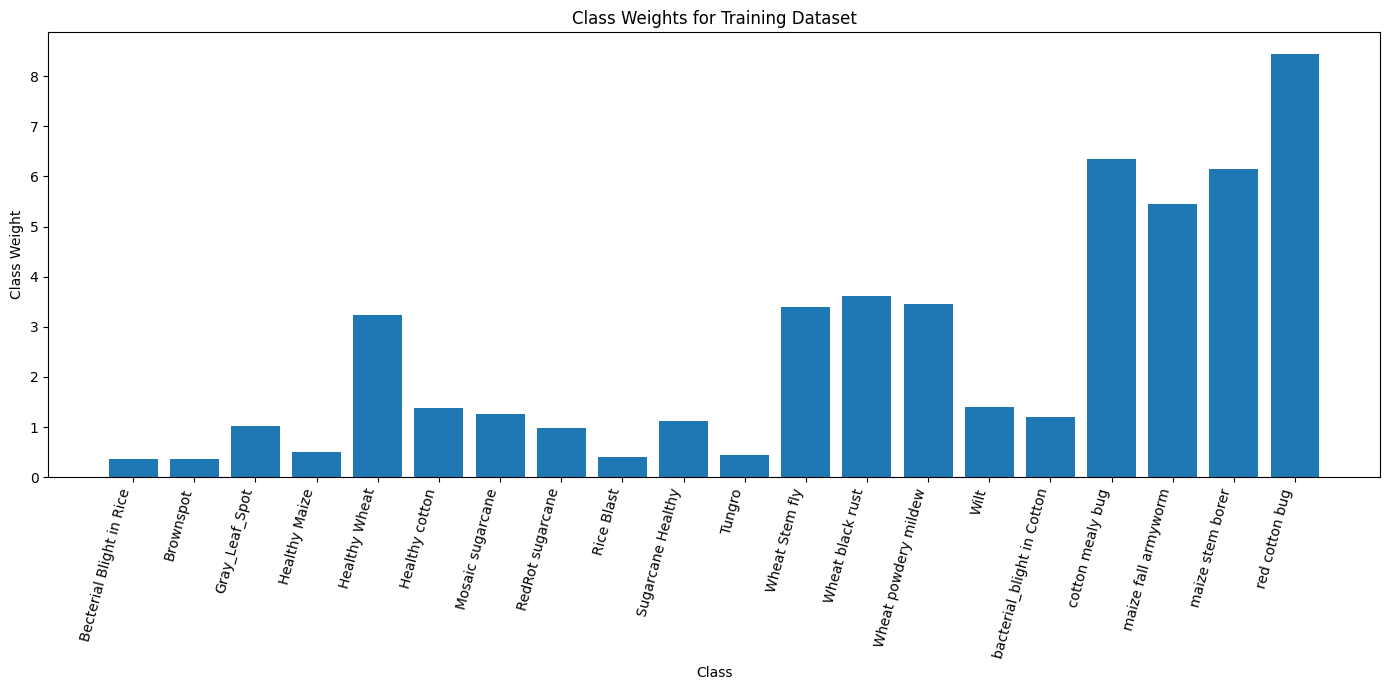

Class weight visualization saved successfully!
Saved to: /content/drive/MyDrive/Group_AIML/Member 05_IT25103052/EDA/IT25103052_class_weights_visualization.png
File exists: True


In [341]:

# CLASS WEIGHT VISUALIZATION
import matplotlib.pyplot as plt
import os

# Create the bar chart using the final matched class weights
plt.figure(figsize=(14, 7))

plt.bar(
    final_class_weights_df["Class Name"],
    final_class_weights_df["Class_Weight"]
)

# Add title and axis labels
plt.title("Class Weights for Training Dataset")
plt.xlabel("Class")
plt.ylabel("Class Weight")

# Rotate class names so they are readable
plt.xticks(rotation=75, ha="right")

# Adjust layout
plt.tight_layout()

# Define the file path inside Member 05 EDA folder
class_weights_graph = os.path.join(
    EDA_DIR,
    "IT25103052_class_weights_visualization.png"
)

# Save the visualization
plt.savefig(
    class_weights_graph,
    dpi=300,
    bbox_inches="tight"
)

# Display the graph
plt.show()

# Confirm that the graph was saved
print("Class weight visualization saved successfully!")
print("Saved to:", class_weights_graph)
print("File exists:", os.path.exists(class_weights_graph))